# 00 · Data Understanding & EDA: "Your Voice" Employee Survey
Safewater Lines · responses as of 21 Oct · source `data/raw/Your Voice- Responses 21 OCT - FINAL.xlsx`

**Goal of this notebook (stage 0):** understand what the data is, how it was put together, what's wrong with it,
and the basic patterns and relationships, *before* any driver analysis, text mining or modelling.

Contents: 1 Workbook · 2 Codebook · 3 Quality · 4 Clean · 5 Demographics · 6 Likert items · 7 Dimensions & reliability ·
8 Correlations · 9 Segments · 10 HR priority · 11 Open text · 12 Save

In [71]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data/raw/Your Voice- Responses 21 OCT - FINAL.xlsx"
OUT = ROOT / "data/processed"

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

BLUE = "#2a78d6"
LIKERT_COLORS = ["#c63d2f", "#ec9a8a", "#dddcd8", "#8fb8ea", "#2a78d6"]   # 1 → 5, diverging around grey

## 1. Workbook inventory

In [72]:
xl = pd.ExcelFile(RAW)
pd.DataFrame(
    [(s, *pd.read_excel(xl, s, header=None).shape) for s in xl.sheet_names],
    columns=["sheet", "rows", "cols"],
)

,sheet,rows,cols
0,Sheet2,15,3
1,SWL - MASTERDATA,329,43
2,Masterdata - do not refer,330,43
3,English,270,43
4,Hindi,26,43
5,Marathi,31,43
6,Tamil,6,43
7,Malayalam,2,43


| sheet | role |
|---|---|
| `SWL - MASTERDATA` | **cleaned master**: all languages merged, tenure fixed, test rows removed → **use this** |
| `Masterdata - do not refer` | earlier copy of the master (1 extra row); marked do-not-use |
| `English`, `Hindi`, `Marathi`, `Tamil`, `Malayalam` | raw form exports per survey language (headers translated back to English) |
| `Sheet2` | pivot of the HR-priority question with a theme mapping |

The raw sheets add up to 269 + 25 + 30 + 5 + 1 = **330**; the master has **327**. The checks below show why.

In [73]:
pd.read_excel(xl, "English", header=None).iloc[1:, 3].astype(str).value_counts().head(8)

3
0 - 3                  104
15 & Above              47
2026-05-03 00:00:00     44
2026-10-05 00:00:00     42
2015-10-01 00:00:00     32
Name: count, dtype: int64

In the raw language sheets, Excel **auto-converted the tenure bands into dates**
(`5 - 10` → 2026-10-05, `3 - 5` → 2026-05-03, `10 - 15` → 2015-10-01, `46300` = a date serial).
The master has them fixed. **Never analyse the raw sheets directly.**

In [74]:
pd.read_excel(xl, "Sheet2", header=2).dropna(how="all", axis=1).dropna(how="all")

,Row Labels,Count of What is one thing you would like HR to do better?,Unnamed: 2
0,Being available and easy to approach,18.0,Approachable
1,Employee activities and engagement,13.0,Engagement
2,Help employees progress in their careers,51.0,Development
3,Help resolve employee problems,35.0,Grievances
4,Improve employee benefits and facilities,51.0,Benefits & Facilities
5,Keeping employees informed,13.0,Communication
6,Listening to employees and their concerns,67.0,Communication
7,Making rules and processes simple,20.0,Process & Policies
8,Recognising and appreciating good work,31.0,R&R
9,Supporting employees when they need help,29.0,Grievances


`Sheet2` maps the 10 HR options to 7 themes (Communication, Development, Benefits, Grievances…). We'll reuse it in §10.

## 2. Load the master and build a codebook
The header spans two rows: row 1 = dimension (merged cells), row 2 = question text.

In [75]:
hdr = pd.read_excel(xl, "SWL - MASTERDATA", header=None, nrows=2)
hdr.T.head(8)

,0,1
0,NaN,Your Workplace Location
1,NaN,Do not want to disclose
2,NaN,Your Current Department
3,NaN,Your years of Service
4,NaN,Gender
5,NaN,Your Full name - This is optional
6,CREDIBILITY,Communication from senior leadership is open and honest.
7,NaN,Our leaders do what they say they will do.


In [76]:
dims = hdr.iloc[0].ffill()
questions = hdr.iloc[1]
questions.iloc[1]

'Do not want to disclose'

Column 2's header says *"Do not want to disclose"*: a header cell got overwritten by a response value.
The `do not refer` sheet shows the real name: **Your Current Designation**.

In [77]:
DIM_CODE = {"CREDIBILITY": "CRE", "RESPECT": "RES", "FAIRNESS": "FAI", "PRIDE": "PRI",
            "CAMARADERIE": "CAM", "OVERALL EMPLOYEE EXPERIENCE": "OVR"}
demo_names = ["location", "designation", "department", "tenure", "gender", "full_name"]
oe_names = ["oe_leaders_trust", "oe_feel_valued", "oe_fairness_concern",
            "oe_value_most", "oe_teamwork", "oe_one_change"]

item_names = [f"{DIM_CODE[d]}{i % 5 + 1}" for i, d in enumerate(dims.iloc[6:36])]
cols = demo_names + item_names + oe_names + ["hr_priority"]
len(cols), item_names[:6]

(43, ['CRE1', 'CRE2', 'CRE3', 'CRE4', 'CRE5', 'RES1'])

In [78]:
codebook = pd.DataFrame({
    "col": cols,
    "block": ["demographic"] * 6 + list(dims.iloc[6:36]) + ["open-ended"] * 6 + ["single-choice"],
    "question": ["Your Current Designation" if i == 1 else q for i, q in enumerate(questions)],
})
codebook

,col,block,question
0,location,demographic,Your Workplace Location
1,designation,demographic,Your Current Designation
2,department,demographic,Your Current Department
3,tenure,demographic,Your years of Service
4,gender,demographic,Gender
5,full_name,demographic,Your Full name - This is optional
6,CRE1,CREDIBILITY,Communication from senior leadership is open and honest.
7,CRE2,CREDIBILITY,Our leaders do what they say they will do.
8,CRE3,CREDIBILITY,I have confidence in the direction of the organization.
9,CRE4,CREDIBILITY,Senior leaders communicate important changes in a timely manner


In [79]:
raw = pd.read_excel(xl, "SWL - MASTERDATA", header=None, skiprows=2, names=cols)
raw.shape

(327, 43)

In [80]:
ITEMS = item_names
DIMS = list(DIM_CODE.values())
OE = oe_names
DEMO = ["location", "designation", "department", "tenure", "gender"]

## 3. Data quality

In [81]:
raw.dtypes.value_counts()

str    43
Name: count, dtype: int64

In [82]:
raw.isna().sum().loc[lambda s: s > 0]

full_name              100
oe_leaders_trust         9
oe_feel_valued          11
oe_fairness_concern     19
oe_value_most            9
oe_teamwork             10
oe_one_change           12
dtype: int64

- Demographics and all 30 Likert items are **100% complete** (forced response)
- `full_name` is optional, and 69% gave it, so **the survey isn't anonymous for most people**. That can push scores up. Drop it from analysis.
- The open-ended questions are 3–6% blank

In [83]:
raw["full_name"].notna().mean().round(3)

np.float64(0.694)

In [84]:
raw.drop(columns="full_name").duplicated().sum()

np.int64(0)

### Likert labels

In [85]:
pd.Series(raw[ITEMS].values.ravel()).value_counts()

Almost always    3991
Usually          2358
Almost Always    1779
Sometimes         981
Rarely            359
Often             173
Almost Never      118
Always             30
Almost never       21
Name: count, dtype: int64

There are 9 labels for a 5-point scale:
- case variants: `Almost always` / `Almost Always`, `Almost never` / `Almost Never`
- `Often` (173) only comes from the **Hindi** form, which used *Often* where the others used *Usually*
- `Always` (30) is the single **Malayalam** respondent, who picked the top option on every question

Mapping: Almost never 1 · Rarely 2 · Sometimes 3 · Usually / Often 4 · Almost always / Always 5

In [86]:
SCALE = {"almost never": 1, "rarely": 2, "sometimes": 3, "usually": 4, "often": 4,
         "almost always": 5, "always": 5}
raw[ITEMS].apply(lambda c: c.str.strip().str.lower().map(SCALE)).isna().sum().sum()

np.int64(0)

### Response-style checks

In [87]:
L = raw[ITEMS].apply(lambda c: c.str.strip().str.lower().map(SCALE))
straight = L.nunique(axis=1).eq(1)
straight.sum(), L.loc[straight, "CRE1"].value_counts().to_dict()

(np.int64(54), {5: 51, 4: 2, 3: 1})

**54 straight-liners (16.5%)** gave the same answer to all 30 items, 51 of them all 5s. That's genuine enthusiasm or
survey fatigue (speeding), and it can't be told apart without timestamps. They also explain the apparent
"duplicate" score patterns. Keep them, but check that results hold without them (§9).

In [88]:
L.std(axis=1).describe().round(2)

count    327.00
mean       0.55
std        0.37
min        0.00
25%        0.31
50%        0.55
75%        0.79
max        1.70
dtype: float64

### Category hygiene

In [89]:
raw["designation"].nunique(), raw["designation"].str.strip().str.title().nunique()

(37, 36)

In [90]:
raw["designation"].value_counts().tail(15)

designation
Sales & operation                   1
BPO Assistant                       1
SALES                               1
Deputy Branch Accountant            1
EXECUTIVE - FRONT OFFICE & ADMIN    1
BRANCH ACCOUNTANT                   1
Branch Accountant                   1
Off role                            1
Supervisor                          1
Runner                              1
Area Sales Manager                  1
Field Supervisor                    1
IMPORT                              1
Import export                       1
DOCUMENT EXECUTIVE                  1
Name: count, dtype: int64

Designation is typed in free text (case variants like `BRANCH ACCOUNTANT` vs `Branch Accountant`, plus departments typed as roles, such as
`SALES`, `IMPORT`). Group it into levels below.

In [91]:
raw["department"].value_counts()

department
Documentation                   59
Sales                           54
Customer Service                51
Finance & Accounts              38
Operations                      36
Customs Clearance               13
Accounts - Trade                11
Pricing                          9
Business Development             8
Billing                          8
Administration                   7
Credit Control                   5
BPO                              5
AMS                              4
Human Resources                  3
Commercial                       2
Marketing                        2
Sales Support                    2
Information Technology           2
Inside Sales                     2
Do not want to disclose          1
FTWZ                             1
DISPATCH                         1
Product / System Development     1
BL release                       1
TRANSPORT & LOGISTICS            1
Name: count, dtype: int64

In [92]:
raw["location"].value_counts()

location
Mumbai         132
Noida           43
Cochin          33
Chennai         24
Kolkata         24
Ahmedabad       12
Hyderabad       11
Nhava Sheva     11
Gandhidham       7
Pune             5
Nairobi          4
Panipat          4
Kanpur           3
Ludhiana         2
Jaipur           2
Bangalore        2
Baroda           2
Coimbatore       1
New Jersey       1
Vizag            1
Tuticorin        1
Mundra           1
Aurangabad       1
Name: count, dtype: int64

## 4. Clean → analysis table `df`

In [93]:
def level(d: str) -> str:
    d = d.strip().lower()
    if any(k in d for k in ["chief", "general manager", "head of"]):
        return "6 Sr Leadership"
    if "assistant manager" in d or "team leader" in d or "supervisor" in d:
        return "4 AM / TL"
    if "manager" in d:
        return "5 Manager+"
    if "senior executive" in d:
        return "3 Sr Executive"
    if "executive" in d:
        return "2 Executive"
    if any(k in d for k in ["junior", "assistant", "runner", "off role"]):
        return "1 Junior / Support"
    return "0 Unclear"

REGION = {
    "West": ["Mumbai", "Nhava Sheva", "Pune", "Ahmedabad", "Gandhidham", "Baroda", "Mundra", "Aurangabad"],
    "North": ["Noida", "Kanpur", "Ludhiana", "Jaipur", "Panipat"],
    "South": ["Cochin", "Chennai", "Hyderabad", "Bangalore", "Coimbatore", "Vizag", "Tuticorin"],
    "East": ["Kolkata"],
    "Overseas": ["Nairobi", "New Jersey"],
}
CITY2REGION = {c: r for r, cs in REGION.items() for c in cs}
TENURE = ["0 - 3", "3 - 5", "5 - 10", "10 - 15", "15 & Above"]

In [94]:
df = raw.drop(columns="full_name").copy()
df[ITEMS] = L
df["level"] = df["designation"].map(level)
df["region"] = df["location"].map(CITY2REGION)
top_dept = df["department"].value_counts().loc[lambda s: s >= 10].index
df["dept_group"] = df["department"].where(df["department"].isin(top_dept), "Other")
df["tenure"] = pd.Categorical(df["tenure"], TENURE, ordered=True)
df["straightliner"] = straight
df["gave_name"] = raw["full_name"].notna()

In [95]:
df["region"].isna().sum(), df["level"].value_counts().sort_index()

(np.int64(0),
 level
 0 Unclear              12
 1 Junior / Support      9
 2 Executive           131
 3 Sr Executive         63
 4 AM / TL              51
 5 Manager+             51
 6 Sr Leadership        10
 Name: count, dtype: int64)

In [96]:
df.loc[df["level"] == "0 Unclear", "designation"].value_counts()

designation
Business Development        2
Trade -Africa               1
Do not want to disclose     1
Agency Network & CSM        1
Sales & operation           1
SALES                       1
Deputy Branch Accountant    1
BRANCH ACCOUNTANT           1
Branch Accountant           1
IMPORT                      1
Import export               1
Name: count, dtype: int64

### Scores
- **Dimension score** = mean of its 5 items (1–5)
- **% favourable** = share of answers that are 4 or 5 (*Usually / Almost always*), the standard engagement-survey KPI
- **Trust Index** = mean of the 25 items in CRE, RES, FAI, PRI, CAM (OVR is kept separate as the outcome block)

In [97]:
for d in DIMS:
    df[d] = df[[f"{d}{i}" for i in range(1, 6)]].mean(axis=1)
TI_ITEMS = [c for c in ITEMS if not c.startswith("OVR")]
df["TRUST_INDEX"] = df[TI_ITEMS].mean(axis=1)
df["fav_pct"] = (df[ITEMS] >= 4).mean(axis=1) * 100

In [98]:
df[DIMS + ["TRUST_INDEX", "fav_pct"]].describe().round(2)

,CRE,RES,FAI,PRI,CAM,OVR,TRUST_INDEX,fav_pct
count,327.00,327.00,327.00,327.00,327.00,327.00,327.00,327.00
mean,4.35,4.32,4.17,4.58,4.35,4.48,4.35,84.92
std,0.75,0.78,0.81,0.58,0.66,0.69,0.64,22.54
min,1.40,1.40,1.00,1.80,1.40,1.60,1.64,0.00
25%,4.00,3.90,3.60,4.40,4.00,4.20,4.00,80.00
50%,4.60,4.60,4.40,4.80,4.60,4.80,4.52,96.67
75%,5.00,5.00,5.00,5.00,5.00,5.00,4.92,100.00
max,5.00,5.00,5.00,5.00,5.00,5.00,5.00,100.00


## 5. Who answered?

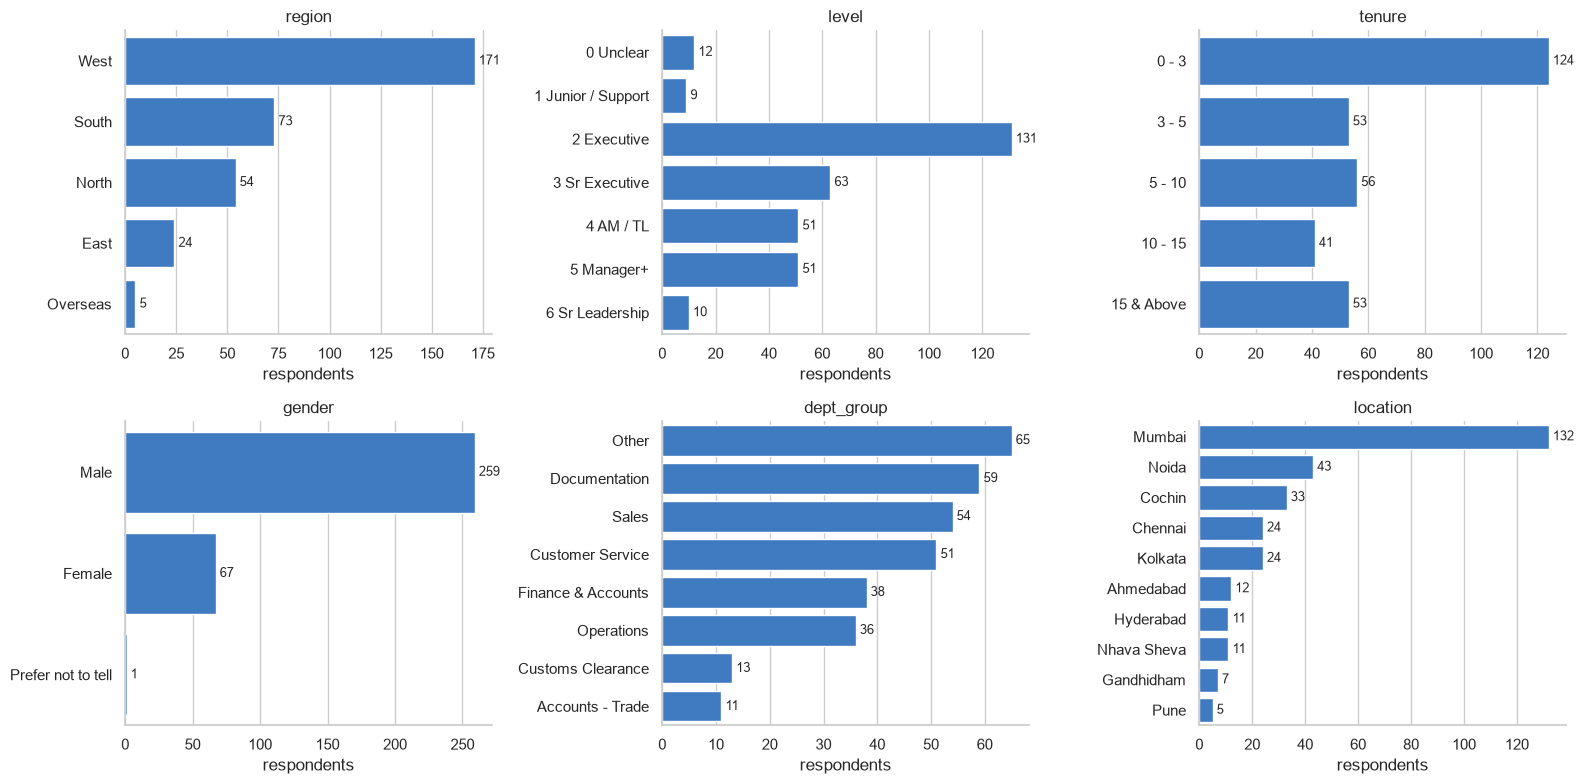

In [99]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, ["region", "level", "tenure", "gender", "dept_group", "location"]):
    vc = df[col].value_counts(sort=col not in ["tenure", "level"]).sort_index() if col in ["tenure", "level"] \
        else df[col].value_counts().head(10)
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color=BLUE)
    ax.bar_label(ax.containers[0], padding=3, fontsize=9)
    ax.set(title=col, xlabel="respondents", ylabel="")
plt.tight_layout()

- **Mumbai = 40%** of responses, and 0–3 years tenure is the biggest group (38%)
- **79% male**: gender cuts will rest on a female n of about 67
- Executive and Sr Executive levels dominate, with very few Sr Leadership. Treat any segment with **n < 10** as anecdotal.

In [100]:
pd.crosstab(df["level"], df["tenure"], margins=True)

tenure,0 - 3,3 - 5,5 - 10,10 - 15,15 & Above,All
level,,,,,,
0 Unclear,2,3,0,3,4,12
1 Junior / Support,4,0,2,3,0,9
2 Executive,63,20,21,14,13,131
3 Sr Executive,30,9,10,5,9,63
4 AM / TL,12,8,15,6,10,51
5 Manager+,10,12,7,10,12,51
6 Sr Leadership,3,1,1,0,5,10
All,124,53,56,41,53,327


Level and tenure are only **weakly** linked (ρ ≈ 0.18, below): many long-tenure Executives. So tenure and level effects are mostly separate.

In [101]:
stats.spearmanr(df["level"].str[0].astype(int), df["tenure"].cat.codes)

SignificanceResult(statistic=np.float64(0.17722810511228432), pvalue=np.float64(0.0012905173954243948))

## 6. Likert items

In [102]:
dist = (df[ITEMS].apply(lambda c: c.value_counts(normalize=True)).T.reindex(columns=[1, 2, 3, 4, 5]).fillna(0) * 100)
dist.index = [f"{c}  {q[:60]}" for c, q in zip(ITEMS, codebook.set_index("col").loc[ITEMS, "question"])]
dist = dist.iloc[::-1]

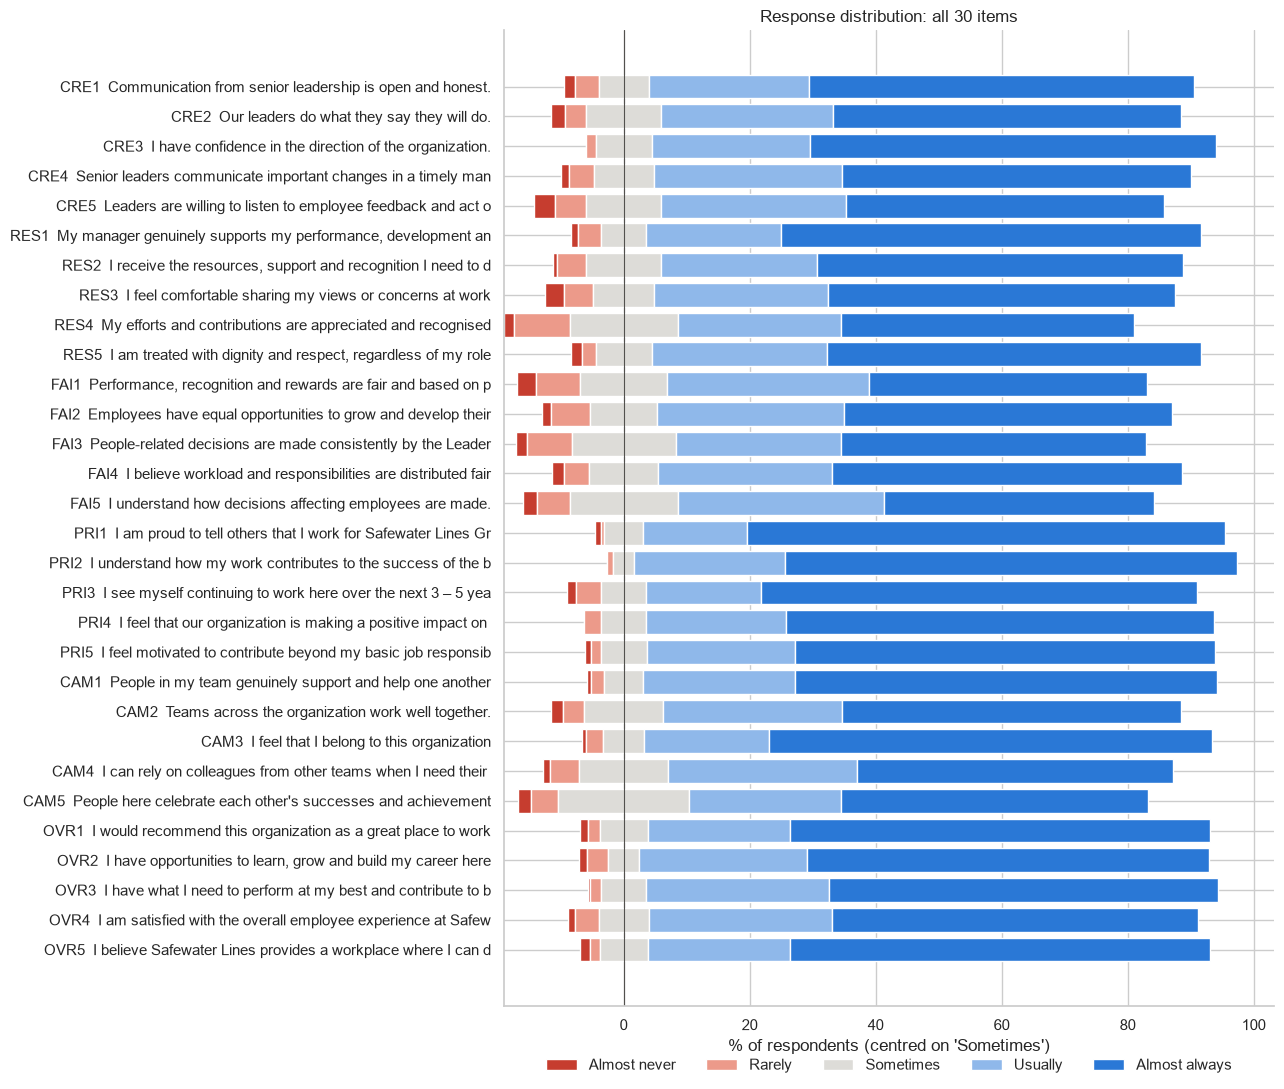

In [103]:
fig, ax = plt.subplots(figsize=(13, 11))
left = -(dist[1] + dist[2] + dist[3] / 2)
for k, color in zip([1, 2, 3, 4, 5], LIKERT_COLORS):
    ax.barh(dist.index, dist[k], left=left, color=color, edgecolor="white", linewidth=1,
            label=["Almost never", "Rarely", "Sometimes", "Usually", "Almost always"][k - 1])
    left = left + dist[k]
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(xlabel="% of respondents (centred on 'Sometimes')", title="Response distribution: all 30 items")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.04), frameon=False)
plt.tight_layout()

In [104]:
item_stats = pd.DataFrame({
    "mean": df[ITEMS].mean(),
    "fav_%": (df[ITEMS] >= 4).mean() * 100,
    "unfav_%": (df[ITEMS] <= 2).mean() * 100,
    "top_box_%": (df[ITEMS] == 5).mean() * 100,
    "skew": df[ITEMS].skew(),
}).round(1)
item_stats.assign(question=codebook.set_index("col")["question"].str[:70]).sort_values("mean")

,mean,fav_%,unfav_%,top_box_%,skew,question
FAI5,4.1,75.5,7.3,42.8,-1.0,I understand how decisions affecting employees are made.
CAM5,4.1,72.8,6.4,48.6,-1.0,People here celebrate each other's successes and achievements.
RES4,4.1,72.5,10.4,46.5,-0.9,My efforts and contributions are appreciated and recognised
FAI1,4.1,76.1,10.1,44.0,-1.1,"Performance, recognition and rewards are fair and based on performance"
FAI3,4.1,74.6,8.9,48.3,-1.0,People-related decisions are made consistently by the Leadership team
CRE5,4.2,79.8,8.3,50.5,-1.4,Leaders are willing to listen to employee feedback and act on it.
CAM4,4.2,80.1,5.8,50.2,-1.2,I can rely on colleagues from other teams when I need their support.
FAI2,4.2,81.7,7.6,52.0,-1.3,Employees have equal opportunities to grow and develop their careers.
CRE2,4.3,82.6,5.5,55.4,-1.5,Our leaders do what they say they will do.
CRE4,4.3,85.3,5.2,55.4,-1.5,Senior leaders communicate important changes in a timely manner


Scores are high across the board, with strong **negative skew / ceiling effect**: top-box is 43–76% depending on the item.
So the useful signal is in the *relative* ranking of items and segments, not the absolute level.

In [105]:
item_stats["fav_%"].describe().round(1)

count    30.0
mean     84.9
std       6.2
min      72.5
25%      81.8
50%      86.8
75%      90.0
max      95.7
Name: fav_%, dtype: float64

## 7. Dimensions & reliability

In [106]:
def cronbach_alpha(x: pd.DataFrame) -> float:
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

rel = pd.DataFrame({
    "mean": [df[d].mean() for d in DIMS],
    "fav_%": [(df[[f"{d}{i}" for i in range(1, 6)]] >= 4).mean().mean() * 100 for d in DIMS],
    "alpha": [cronbach_alpha(df[[f"{d}{i}" for i in range(1, 6)]]) for d in DIMS],
}, index=DIMS).round(2)
rel.sort_values("mean")

,mean,fav_%,alpha
FAI,4.17,78.23,0.86
RES,4.32,82.63,0.88
CRE,4.35,84.77,0.88
CAM,4.35,83.30,0.79
OVR,4.48,89.42,0.90
PRI,4.58,91.19,0.84


All dimensions have α ≈ 0.79–0.90, so the items hang together (Camaraderie is the weakest at 0.79).
Overall α across all 30 items is 0.97,
which hints that respondents answer with one general mood (halo effect).

In [107]:
alpha_all = cronbach_alpha(df[ITEMS])
alpha_all

np.float64(0.9664818681466951)

In [108]:
def item_total(d):
    sub = df[[f"{d}{i}" for i in range(1, 6)]]
    return sub.apply(lambda c: c.corr(sub.drop(columns=c.name).sum(axis=1)))

pd.concat([item_total(d) for d in DIMS]).round(2).sort_values().head(8)

CAM3    0.51
CAM1    0.53
CAM4    0.59
CAM2    0.60
PRI2    0.61
PRI1    0.62
PRI4    0.63
FAI5    0.63
dtype: float64

The weakest item-total links show which items fit their dimension least, i.e. which carry their own signal.

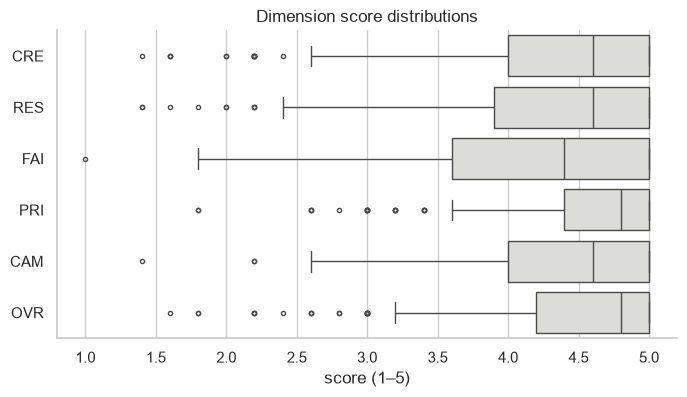

In [109]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df[DIMS], orient="h", color="#dddcd8", fliersize=3, ax=ax)
ax.set(xlabel="score (1–5)", title="Dimension score distributions");

## 8. Correlations

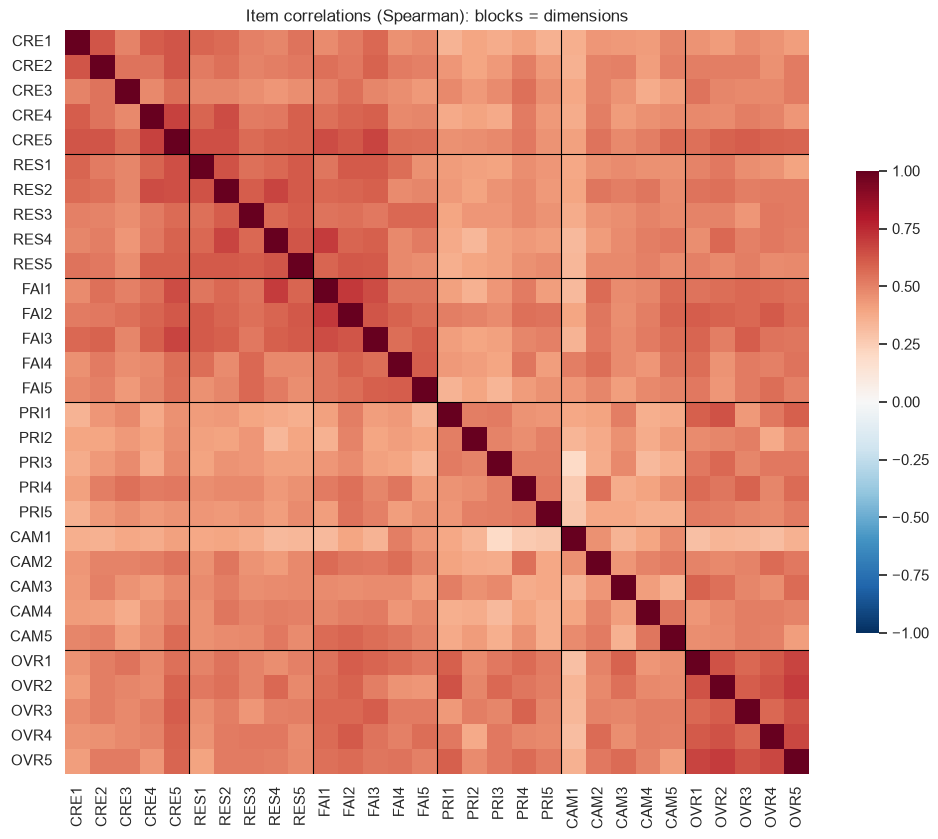

In [110]:
item_corr = df[ITEMS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(item_corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.6})
for b in range(5, 30, 5):
    ax.axhline(b, color="black", lw=0.8); ax.axvline(b, color="black", lw=0.8)
ax.set_title("Item correlations (Spearman): blocks = dimensions");

In [111]:
within = np.mean([item_corr.loc[[f"{d}{i}" for i in range(1, 6)], [f"{d}{i}" for i in range(1, 6)]]
                  .values[np.triu_indices(5, 1)].mean() for d in DIMS])
overall = item_corr.values[np.triu_indices(30, 1)].mean()
round(within, 2), round(overall, 2)

(np.float64(0.56), np.float64(0.49))

Average within-dimension correlation is only a bit above the overall average, so the 6 dimensions are
**not strongly separate** in this data. Check this formally later (EFA/CFA) before treating the dimensions as distinct drivers.

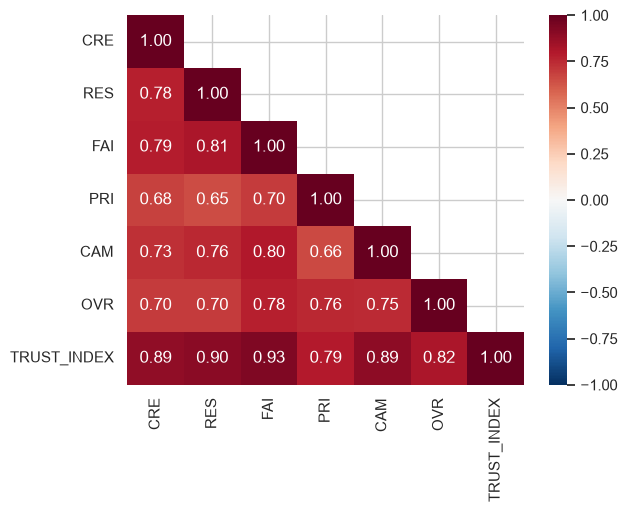

In [112]:
dim_corr = df[DIMS + ["TRUST_INDEX"]].corr(method="spearman")
sns.heatmap(dim_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(dim_corr, dtype=bool), 1));

### What moves together with the outcome items?
Outcome-type items: **OVR1** *recommend as a great place to work* (eNPS-like), **PRI3** *see myself here in 3–5 years* (retention intent),
**OVR4** *overall satisfaction*.

In [113]:
OUTCOMES = {"OVR1": "recommend", "PRI3": "stay 3–5 yrs", "OVR4": "satisfied"}
drivers = [c for c in ITEMS if c not in OUTCOMES]
out_corr = df[drivers + list(OUTCOMES)].corr(method="spearman").loc[drivers, list(OUTCOMES)]
out_corr.columns = OUTCOMES.values()
out_corr.assign(q=codebook.set_index("col").loc[drivers, "question"].str[:60]).sort_values("stay 3–5 yrs", ascending=False).head(10).round(2)

,recommend,stay 3–5 yrs,satisfied,q
OVR2,0.64,0.57,0.64,"I have opportunities to learn, grow and build my career here"
OVR5,0.68,0.53,0.67,I believe Safewater Lines provides a workplace where I can d
PRI1,0.60,0.52,0.53,I am proud to tell others that I work for Safewater Lines Gr
PRI5,0.52,0.51,0.48,I feel motivated to contribute beyond my basic job responsib
PRI4,0.57,0.51,0.49,I feel that our organization is making a positive impact on
PRI2,0.47,0.50,0.38,I understand how my work contributes to the success of the b
OVR3,0.58,0.49,0.57,I have what I need to perform at my best and contribute to b
CRE5,0.55,0.48,0.59,Leaders are willing to listen to employee feedback and act o
CAM3,0.59,0.48,0.46,I feel that I belong to this organization
FAI2,0.61,0.47,0.62,Employees have equal opportunities to grow and develop their


In [114]:
out_corr.assign(q=codebook.set_index("col").loc[drivers, "question"].str[:60]).sort_values("stay 3–5 yrs").head(5).round(2)

,recommend,stay 3–5 yrs,satisfied,q
CAM1,0.30,0.20,0.31,People in my team genuinely support and help one another
CAM4,0.44,0.32,0.52,I can rely on colleagues from other teams when I need their
FAI5,0.53,0.34,0.56,I understand how decisions affecting employees are made.
CAM5,0.46,0.36,0.51,People here celebrate each other's successes and achievement
CRE1,0.45,0.37,0.45,Communication from senior leadership is open and honest.


These are bivariate correlations only, inflated by the halo effect and straight-liners. Use them to shortlist candidates
for the driver analysis (relative-weights / regression), not as conclusions.

In [115]:
df[["TRUST_INDEX", "OVR"]].corr(method="spearman").iloc[0, 1].round(2)

np.float64(0.82)

## 9. Segments
Mean Trust Index and % favourable by group, plus a Kruskal–Wallis test. Segments with n < 10 are flagged.

In [116]:
def seg(col, data=df, score="TRUST_INDEX"):
    g = data.groupby(col, observed=True)
    t = pd.DataFrame({"n": g.size(), "mean": g[score].mean(), "fav_%": g["fav_pct"].mean()}).round(2)
    t["small_n"] = t["n"] < 10
    groups = [x[score].values for _, x in g if len(x) >= 10]
    p = stats.kruskal(*groups).pvalue if len(groups) > 1 else np.nan
    return t, round(p, 4)

In [117]:
seg("tenure")

(              n  mean  fav_%  small_n
 tenure                               
 0 - 3       124  4.30  83.20    False
 3 - 5        53  4.21  81.45    False
 5 - 10       56  4.38  84.88    False
 10 - 15      41  4.70  95.53    False
 15 & Above   53  4.32  84.28    False,
 np.float64(0.0012))

In [118]:
seg("level")

(                      n  mean  fav_%  small_n
 level                                        
 0 Unclear            12  4.20  84.44    False
 1 Junior / Support    9  4.71  93.33     True
 2 Executive         131  4.40  86.01    False
 3 Sr Executive       63  4.22  80.85    False
 4 AM / TL            51  4.26  81.44    False
 5 Manager+           51  4.44  88.24    False
 6 Sr Leadership      10  4.49  90.33    False,
 np.float64(0.2375))

In [119]:
seg("region")

(            n  mean  fav_%  small_n
 region                             
 East       24  4.35  88.47    False
 North      54  4.49  87.47    False
 Overseas    5  4.08  75.33     True
 South      73  4.50  90.68    False
 West      171  4.26  81.44    False,
 np.float64(0.0378))

In [120]:
seg("dept_group")

(                     n  mean  fav_%  small_n
 dept_group                                  
 Accounts - Trade    11  4.33  86.06    False
 Customer Service    51  4.09  75.75    False
 Customs Clearance   13  4.45  88.72    False
 Documentation       59  4.41  85.76    False
 Finance & Accounts  38  4.50  91.05    False
 Operations          36  4.61  93.33    False
 Other               65  4.31  82.72    False
 Sales               54  4.31  84.26    False,
 np.float64(0.0113))

In [121]:
seg("gender")

(                      n  mean  fav_%  small_n
 gender                                       
 Female               67  4.25  81.19    False
 Male                259  4.39  86.14    False
 Prefer not to tell    1  3.00  20.00     True,
 np.float64(0.0837))

In [122]:
seg("gave_name")

(             n  mean  fav_%  small_n
 gave_name                           
 False      100  4.20  79.20    False
 True       227  4.42  87.44    False,
 np.float64(0.0053))

Named vs anonymous: if named respondents score higher, that's a sign of social-desirability bias in a non-anonymous survey.

In [123]:
pd.DataFrame({c: seg(c)[1] for c in ["tenure", "level", "region", "dept_group", "gender", "gave_name"]},
             index=["kruskal_p"]).T

,kruskal_p
tenure,0.0012
level,0.2375
region,0.0378
dept_group,0.0113
gender,0.0837
gave_name,0.0053


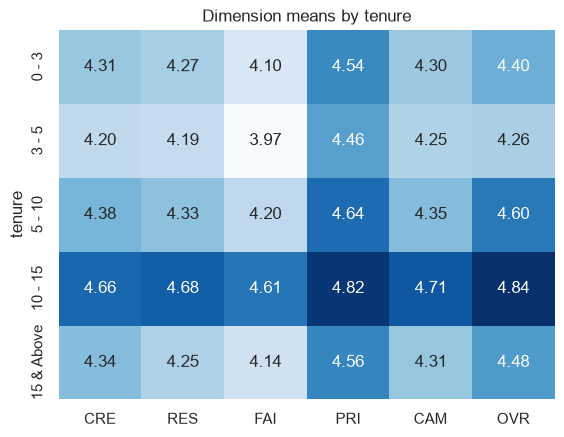

In [124]:
seg_dim = df.groupby("tenure", observed=True)[DIMS].mean()
sns.heatmap(seg_dim, annot=True, fmt=".2f", cmap="Blues", cbar=False)
plt.title("Dimension means by tenure");

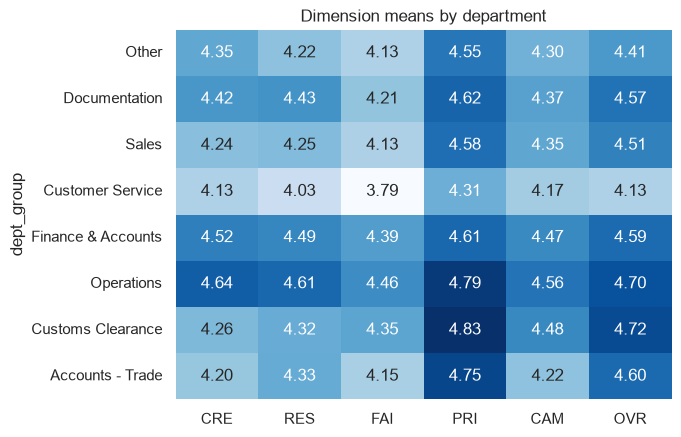

In [125]:
seg_dim = df.groupby("dept_group")[DIMS].mean().assign(n=df["dept_group"].value_counts()).sort_values("n", ascending=False)
sns.heatmap(seg_dim[DIMS], annot=True, fmt=".2f", cmap="Blues", cbar=False)
plt.title("Dimension means by department");

### Robustness: drop the straight-liners

In [126]:
pd.DataFrame({
    "all": df[DIMS].mean(),
    "no_straightliners": df.loc[~df["straightliner"], DIMS].mean(),
}).assign(diff=lambda t: t["no_straightliners"] - t["all"]).round(2)

,all,no_straightliners,diff
CRE,4.35,4.24,-0.11
RES,4.32,4.20,-0.12
FAI,4.17,4.02,-0.15
PRI,4.58,4.51,-0.07
CAM,4.35,4.24,-0.11
OVR,4.48,4.39,-0.09


In [127]:
pd.DataFrame({c: [seg(c)[1], seg(c, df[~df["straightliner"]])[1]] for c in ["tenure", "level", "region", "dept_group", "gender"]},
             index=["p_all", "p_no_straight"]).T

,p_all,p_no_straight
tenure,0.0012,0.0017
level,0.2375,0.0613
region,0.0378,0.0516
dept_group,0.0113,0.1460
gender,0.0837,0.1263


Who straight-lines?

In [128]:
pd.crosstab(df["tenure"], df["straightliner"], normalize="index").round(2)

straightliner,False,True
tenure,,
0 - 3,0.85,0.15
3 - 5,0.89,0.11
5 - 10,0.80,0.20
10 - 15,0.76,0.24
15 & Above,0.85,0.15


## 10. HR priority (single choice)

In [129]:
theme = pd.read_excel(xl, "Sheet2", header=2).iloc[:10, [0, 2]].set_axis(["option", "theme"], axis=1)
theme["theme"] = theme["theme"].str.strip()
df["hr_theme"] = df["hr_priority"].map(dict(zip(theme["option"], theme["theme"])))
df["hr_theme"].isna().sum()

np.int64(0)

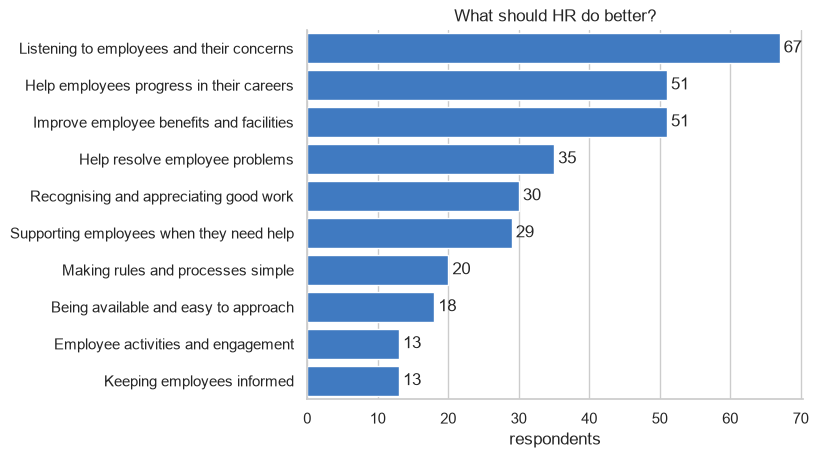

In [130]:
hr = df["hr_priority"].value_counts()
ax = sns.barplot(x=hr.values, y=hr.index, color=BLUE)
ax.bar_label(ax.containers[0], padding=3)
ax.set(title="What should HR do better?", xlabel="respondents", ylabel="");

In [131]:
df["hr_theme"].value_counts(normalize=True).round(3) * 100

hr_theme
Communication            24.5
Grievances               19.6
Development              15.6
Benefits & Facilities    15.6
R&R                       9.2
Process & Policies        6.1
Approachable              5.5
Engagement                4.0
Name: proportion, dtype: float64

In [132]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2, p, *_ = stats.chi2_contingency(ct)
    return round(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), 3), round(p, 4)

pd.DataFrame({c: cramers_v(df[c], df["hr_theme"]) for c in ["tenure", "level", "region", "dept_group", "gender"]},
             index=["cramers_v", "p"]).T

,cramers_v,p
tenure,0.155,0.3046
level,0.134,0.7607
region,0.157,0.2569
dept_group,0.188,0.0026
gender,0.139,0.5495


In [133]:
pd.crosstab(df["tenure"], df["hr_theme"], normalize="index").round(2)

hr_theme,Approachable,Benefits & Facilities,Communication,Development,Engagement,Grievances,Process & Policies,R&R
tenure,,,,,,,,
0 - 3,0.05,0.14,0.24,0.21,0.04,0.19,0.03,0.10
3 - 5,0.08,0.11,0.25,0.13,0.08,0.23,0.08,0.06
5 - 10,0.04,0.20,0.23,0.09,0.04,0.23,0.12,0.05
10 - 15,0.02,0.20,0.37,0.15,0.02,0.17,0.00,0.07
15 & Above,0.09,0.17,0.17,0.13,0.02,0.15,0.09,0.17


In [134]:
df.groupby("hr_theme")[["TRUST_INDEX", "PRI3"]].mean().round(2).sort_values("TRUST_INDEX")

,TRUST_INDEX,PRI3
hr_theme,,
Process & Policies,4.18,4.10
Communication,4.32,4.50
Benefits & Facilities,4.33,4.57
Grievances,4.33,4.42
Approachable,4.34,4.39
Engagement,4.39,4.62
R&R,4.43,4.60
Development,4.47,4.61


The HR priority also tells us something about how people score: does the group asking for "Communication" or "Grievances" have lower trust?

## 11. Open-ended text: quick profile (full text mining comes later)

In [135]:
txt = df[OE].astype("string").apply(lambda c: c.str.strip())
EMPTY = r"^(nil|na|n/a|no|none|nothing|ok|okay|yes|good|-|\.|no comments?|nothing to say|all good|no suggestions?)\.?$"
profile = pd.DataFrame({
    "blank_%": txt.isna().mean() * 100,
    "non_answer_%": txt.apply(lambda c: c.str.lower().str.fullmatch(EMPTY).fillna(False)).mean() * 100,
    "median_words": txt.apply(lambda c: c.str.split().str.len()).median(),
    "max_words": txt.apply(lambda c: c.str.split().str.len()).max(),
}).round(1)
profile

,blank_%,non_answer_%,median_words,max_words
oe_leaders_trust,2.8,5.2,8.0,227
oe_feel_valued,3.4,5.5,8.0,189
oe_fairness_concern,5.8,10.1,7.0,150
oe_value_most,2.8,4.6,6.0,89
oe_teamwork,3.1,4.6,7.0,132
oe_one_change,3.7,6.4,8.0,353


In [136]:
txt.apply(lambda c: c.str.split().str.len()).astype("Float64").mean(axis=1).groupby(df["level"]).median().round(1)

level
0 Unclear              8.2
1 Junior / Support     3.3
2 Executive            8.6
3 Sr Executive         8.5
4 AM / TL              7.4
5 Manager+             8.5
6 Sr Leadership       13.2
dtype: Float64

In [137]:
STOP = set("""a an the and or of to in on for with is are be we our us i my me it this that as at by from more
should can could would will do does have has employees employee all their them they there so not also very
any some which what who when how be been being into about than then just make better give need""".split())

def top_words(s, n=12):
    w = s.dropna().str.lower().str.findall(r"[a-z]{3,}").explode()
    return w[~w.isin(STOP)].value_counts().head(n).index.tolist()

pd.Series({c: ", ".join(top_words(txt[c])) for c in OE})

oe_leaders_trust       senior, leaders, trust, communication, build, communicate, openly, team, dec...
oe_feel_valued         work, feel, support, valued, feedback, contributions, efforts, recognition, ...
oe_fairness_concern    opportunities, fairness, recognition, concern, growth, help, equal, feel, bi...
oe_value_most          work, culture, teamwork, value, supportive, lose, want, never, support, team...
oe_teamwork            communication, team, improve, teams, other, each, work, teamwork, between, h...
oe_one_change          work, communication, improve, feel, feedback, experience, help, opportunitie...
dtype: str

In [138]:
txt["oe_fairness_concern"].dropna().sample(8, random_state=1).tolist()

['NOWHERE',
 'Opportunities for growth, Promotions',
 'Fairness in promotions and recognition.',
 'na',
 'good management',
 'HONEST COMMUNICATION',
 'Biasness, favouratism',
 '-']

Some answers read very polished and similar ("Communicate more openly and transparently…"), possibly
suggestion-driven or machine-assisted. Check for near-duplicate text at the text-mining stage.

In [139]:
txt.apply(lambda c: c.str.lower().duplicated(keep=False) & c.notna()).sum()

oe_leaders_trust       33
oe_feel_valued         38
oe_fairness_concern    47
oe_value_most          47
oe_teamwork            29
oe_one_change          24
dtype: int64

## 12. Save processed data

In [140]:
OUT.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT / "survey_clean.csv", index=False)
codebook.to_csv(OUT / "codebook.csv", index=False)
df.shape

(327, 56)

## Summary: what we know before any modelling

**The data**
- 327 usable responses (330 raw across 5 language forms, minus 3 test/incomplete rows) · 30 Likert items in 6 GPTW-style
  dimensions · 6 open-ended questions · 1 HR-priority choice · 5 demographics
- Fixed during cleaning: 9 Likert labels → 1–5 scale (the Hindi form used *Often*), a broken designation header,
  free-text designations → 7 levels, 23 cities → 5 regions, departments with n < 10 → Other
- Raw language sheets have tenure converted to dates by Excel, so always work from `SWL - MASTERDATA`

**Response quality: the biggest caveat**
- Very positive: 85% favourable overall, Trust Index 4.35 / 5, strong ceiling effect
- **16.5% straight-liners** (51 all-5s), and **69% gave their name**. Named respondents score significantly higher
  (4.42 vs 4.20, p = 0.005), which is **social-desirability bias**. Read every score as an upper bound.
- α = 0.97 across all items: one general mood (halo) dominates, and the 6 dimensions aren't clearly separate

**Where it's weakest (relative ranking)**
- **Fairness** is the lowest dimension (4.17, 78% favourable). The lowest items: *understanding how people decisions are made*,
  *rewards based on performance*, *consistent decisions without favouritism*, plus *recognition of efforts* (RES4)
  and *celebrating success* (CAM5)
- **Pride** is highest (4.58): people are proud and understand their contribution

**Relationships**
- Retention intent (*see myself here 3–5 yrs*) moves most with **career growth (OVR2)**, meaningful work, pride, and
  leaders acting on feedback. Team-level support (CAM1) barely relates to it.
- **Tenure** has the most robust segment effect (p ≈ 0.001, holds without straight-liners): a **dip at 3–5 yrs (4.21)**
  and a peak at 10–15 yrs (4.70). Watch the mid-tenure group for attrition risk.
- Region (West lowest) and department (**Customer Service lowest, 4.09**) differences are borderline and weaken once straight-liners are removed
- HR asks: **Communication / listening (25%)**, Grievances (20%), Development (16%), Benefits (16%). The choice differs by
  department (Cramér's V 0.19, p = 0.003), not by tenure, level or gender.

**Next steps (stage 1)**
1. Factor analysis (EFA/CFA) to test whether the 6 dimensions hold, or whether 1–2 factors explain the data
2. Driver analysis on retention intent / recommend (relative weights, ordinal regression), with straight-liners as a sensitivity check
3. Theme coding of the 6 open-ended questions (clean out non-answers; ~5–10% are "na / nothing / -")
4. Segment deep-dives: 3–5 yr tenure, Customer Service, West region, women

---
# Annexure

## A. Abbreviations & terms

**Survey dimensions** (item codes = dimension + number, e.g. `FAI3`)

| Short form | Meaning |
|---|---|
| CRE | Credibility: leaders communicate openly, keep promises, act on feedback |
| RES | Respect: manager support, resources, recognition, dignity |
| FAI | Fairness: rewards, opportunities, unbiased decisions, workload |
| PRI | Pride: pride in the company, purpose, intent to stay |
| CAM | Camaraderie: team support, cross-team work, belonging |
| OVR | Overall Employee Experience: recommend, growth, satisfaction (used as the outcome block) |
| OE | Open-ended (free-text) question |

**Metrics**

| Term | Meaning |
|---|---|
| Dimension score | Mean of the 5 items in a dimension, on a 1–5 scale |
| Trust Index (`TRUST_INDEX`) | Mean of the 25 items in CRE + RES + FAI + PRI + CAM (OVR excluded) |
| % favourable (`fav_%`, `fav_pct`) | Share of answers that are 4 or 5 (*Usually / Almost always*) |
| % unfavourable (`unfav_%`) | Share of answers that are 1 or 2 (*Almost never / Rarely*) |
| Top-box % | Share of answers that are 5 (*Almost always*) |
| Straight-liner | Respondent who gave the identical answer to all 30 items |
| Ceiling effect | Most answers bunched at the top of the scale, so differences are hard to see |
| Halo effect | One general feeling colours answers to every question |
| Social-desirability bias | Answering more positively than you feel, e.g. when your name is attached |
| Item-total correlation | How well an item agrees with the rest of its dimension |
| Retention intent | Item `PRI3`: *I see myself continuing to work here over the next 3–5 years* |

**Statistics**

| Symbol / term | Meaning |
|---|---|
| n | Number of respondents in a group (n < 10 is flagged as too small to trust) |
| p / p-value | Probability of a difference this big by chance alone; p < 0.05 = statistically significant |
| ρ (rho) / Spearman | Rank correlation from −1 to +1; suits ordinal Likert data |
| α (alpha) / Cronbach's alpha | Internal consistency of a set of items; ≥ 0.7 acceptable, ≥ 0.8 good, > 0.95 possibly redundant |
| Kruskal–Wallis | Non-parametric test of whether 3+ groups differ (rank-based ANOVA) |
| Mann–Whitney U | Non-parametric test of whether 2 groups differ |
| χ² (chi-square) | Test of association between two categorical variables |
| Cramér's V | Strength of that association, 0–1 (≈0.1 weak, ≈0.3 moderate, ≥0.5 strong) |
| Skew | Asymmetry of a distribution; negative = long tail to the low end |
| EFA / CFA | Exploratory / Confirmatory Factor Analysis: tests whether items group into the assumed dimensions |

**Organisation & business terms**

| Short form | Meaning |
|---|---|
| SWL | Safewater Lines (the company) |
| GPTW | Great Place to Work®: the survey framework these 5 dimensions come from |
| eNPS | Employee Net Promoter Score; `OVR1` (*would recommend*) is the closest item here |
| HR | Human Resources |
| AM / TL | Assistant Manager / Team Leader (level band) |
| Sr | Senior |
| HOD | Head of Department |
| CFO | Chief Financial Officer |
| BPO | Business Process Outsourcing (a department) |
| BD | Business Development |
| CSM | Customer Success Manager (in the designation *Agency Network & CSM*) |
| BL | Bill of Lading (shipping document; department *BL release*) |
| FTWZ | Free Trade Warehousing Zone (a department) |
| AMS | Department name as entered; in freight forwarding usually *Automated Manifest System* (US customs filing). Confirm with SWL. |
| R&R | Rewards & Recognition (HR theme) |

## B. Question codebook

| Code | Block | Question (English master wording) |
|---|---|---|
| `location` | demographic | Your Workplace Location |
| `designation` | demographic | Your Current Designation |
| `department` | demographic | Your Current Department |
| `tenure` | demographic | Your years of Service |
| `gender` | demographic | Gender |
| `CRE1` | Credibility | Communication from senior leadership is open and honest. |
| `CRE2` | Credibility | Our leaders do what they say they will do. |
| `CRE3` | Credibility | I have confidence in the direction of the organization. |
| `CRE4` | Credibility | Senior leaders communicate important changes in a timely manner |
| `CRE5` | Credibility | Leaders are willing to listen to employee feedback and act on it. |
| `RES1` | Respect | My manager genuinely supports my performance, development and well-being. |
| `RES2` | Respect | I receive the resources, support and recognition I need to do my job well. |
| `RES3` | Respect | I feel comfortable sharing my views or concerns at work |
| `RES4` | Respect | My efforts and contributions are appreciated and recognised |
| `RES5` | Respect | I am treated with dignity and respect, regardless of my role or position. |
| `FAI1` | Fairness | Performance, recognition and rewards are fair and based on performance. |
| `FAI2` | Fairness | Employees have equal opportunities to grow and develop their careers. |
| `FAI3` | Fairness | People-related decisions are made consistently by the Leadership team without favoritism or bias. |
| `FAI4` | Fairness | I believe workload and responsibilities are distributed fairly within my team. |
| `FAI5` | Fairness | I understand how decisions affecting employees are made. |
| `PRI1` | Pride | I am proud to tell others that I work for Safewater Lines Group |
| `PRI2` | Pride | I understand how my work contributes to the success of the business. |
| `PRI3` | Pride | I see myself continuing to work here over the next 3 – 5 years. |
| `PRI4` | Pride | I feel that our organization is making a positive impact on our customers and business. |
| `PRI5` | Pride | I feel motivated to contribute beyond my basic job responsibilities when the business needs it. |
| `CAM1` | Camaraderie | People in my team genuinely support and help one another |
| `CAM2` | Camaraderie | Teams across the organization work well together. |
| `CAM3` | Camaraderie | I feel that I belong to this organization |
| `CAM4` | Camaraderie | I can rely on colleagues from other teams when I need their support. |
| `CAM5` | Camaraderie | People here celebrate each other's successes and achievements. |
| `OVR1` | Overall Employee Experience | I would recommend this organization as a great place to work. |
| `OVR2` | Overall Employee Experience | I have opportunities to learn, grow and build my career here. |
| `OVR3` | Overall Employee Experience | I have what I need to perform at my best and contribute to business success. |
| `OVR4` | Overall Employee Experience | I am satisfied with the overall employee experience at Safewater Lines. |
| `OVR5` | Overall Employee Experience | I believe Safewater Lines provides a workplace where I can do meaningful and fulfilling work. |
| `oe_leaders_trust` | open-ended | What is one thing our senior leaders could do better to build greater trust among employees? |
| `oe_feel_valued` | open-ended | What is one thing we could do to make you feel more valued, supported or respected? |
| `oe_fairness_concern` | open-ended | Where do you see the biggest concern about fairness in the organization? |
| `oe_value_most` | open-ended | What is the one thing about our organization that you value most and would never want us to lose? |
| `oe_teamwork` | open-ended | What is one thing we could do to improve teamwork and collaboration? |
| `oe_one_change` | open-ended | If you could make one change to improve the employee experience, what would it be? |
| `hr_priority` | single-choice | What is one thing you would like HR to do better? |

Translated forms (Hindi, Marathi, Tamil, Malayalam) used slightly different English wording for the same items.

## C. Variables created in this notebook (`data/processed/survey_clean.csv`)

| Column | Type | Definition |
|---|---|---|
| `CRE1` … `OVR5` | int 1–5 | Likert answers converted to numbers (see D.1) |
| `CRE`, `RES`, `FAI`, `PRI`, `CAM`, `OVR` | float 1–5 | Dimension scores: mean of 5 items |
| `TRUST_INDEX` | float 1–5 | Mean of 25 items (all dimensions except OVR) |
| `fav_pct` | float 0–100 | Respondent's % of the 30 answers that are 4 or 5 |
| `level` | category | Designation grouped into 7 levels (see D.2) |
| `region` | category | City grouped into 5 regions (see D.3) |
| `dept_group` | category | Department, with those under 10 respondents merged into *Other* |
| `hr_theme` | category | HR-priority option grouped into 8 themes (see D.4) |
| `straightliner` | bool | Same answer to all 30 items |
| `gave_name` | bool | Filled in the optional name field (the name itself is dropped) |

`full_name` is **removed** from all processed outputs.

## D. Mappings used

**D.1 Likert scale**

| Raw label(s) | Score |
|---|---|
| Almost never · Almost Never | 1 |
| Rarely | 2 |
| Sometimes | 3 |
| Usually · Often (Hindi form) | 4 |
| Almost always · Almost Always · Always (Malayalam form) | 5 |

**D.2 Level** (keyword rules, checked in this order)

| Level | Designations containing |
|---|---|
| 6 Sr Leadership | chief, general manager, head of |
| 4 AM / TL | assistant manager, team leader, supervisor |
| 5 Manager+ | manager (Manager, Sr/Deputy/Branch/Area/Project Manager…) |
| 3 Sr Executive | senior executive |
| 2 Executive | executive |
| 1 Junior / Support | junior, assistant, runner, off role |
| 0 Unclear | anything else (e.g. *SALES*, *IMPORT*, *Branch Accountant*, *Do not want to disclose*) |

**D.3 Region**

| Region | Locations |
|---|---|
| West | Mumbai, Nhava Sheva, Pune, Ahmedabad, Gandhidham, Baroda, Mundra, Aurangabad |
| North | Noida, Kanpur, Ludhiana, Jaipur, Panipat |
| South | Cochin, Chennai, Hyderabad, Bangalore, Coimbatore, Vizag, Tuticorin |
| East | Kolkata |
| Overseas | Nairobi, New Jersey |

**D.4 HR theme** (from the workbook's `Sheet2`)

| Theme | HR-priority options |
|---|---|
| Communication | Listening to employees and their concerns · Keeping employees informed |
| Grievances | Help resolve employee problems · Supporting employees when they need help |
| Development | Help employees progress in their careers |
| Benefits & Facilities | Improve employee benefits and facilities |
| R&R | Recognising and appreciating good work |
| Process & Policies | Making rules and processes simple |
| Approachable | Being available and easy to approach |
| Engagement | Employee activities and engagement |

## E. Data sources & lineage

| Item | Detail |
|---|---|
| Source file | `data/raw/Your Voice- Responses 21 OCT - FINAL.xlsx` (responses as of 21 Oct), read-only |
| Sheet used | `SWL - MASTERDATA`: 327 responses × 43 columns, 2-row header (dimension + question) |
| Sheets not used | `Masterdata - do not refer` (older copy, 328 rows) · `English` 269 · `Hindi` 25 · `Marathi` 30 · `Tamil` 5 · `Malayalam` 1 (raw form exports; tenure corrupted into dates) · `Sheet2` (HR pivot, used only for the theme mapping) |
| Raw → master | 330 raw rows → 327 (3 test/incomplete rows removed: e.g. designation `xxx`, a row of `1`s and blanks) |
| Master → clean | Likert mapped to 1–5, designation header fixed, name dropped, derived columns added |
| Outputs | `data/processed/survey_clean.csv` (327 × 56) · `data/processed/codebook.csv` (43 rows) |
| Environment | Python 3.14 via uv (`pyproject.toml` / `uv.lock`): pandas, numpy, scipy, matplotlib, seaborn, openpyxl |